<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%9B%D0%914_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> Був присутній на парі.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Path to dataset files: /kaggle/input/car-price-prediction


In [2]:
import os
import pandas as pd
import numpy as np
file_name = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, file_name))
print(f"Розмірність датасету (об'єкти, ознаки): {df.shape}")
print("\nІнформація про стовпці та типи даних:")
df.info()
print("\nЦільова змінна: 'price'")
display(df.head())
df.describe()

Розмірність датасету (об'єкти, ознаки): (205, 26)

Інформація про стовпці та типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cy

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [3]:
print("Пропущені значення:")
print(df.isnull().sum()[df.isnull().sum() > 0])
if df.isnull().sum().sum() == 0:
    print("Пропусків немає.")
print(f"\nПовних дублікатів у датасеті: {df.duplicated().sum()}")
print(f"Змістовних дублікатів (без car_ID): {df.drop('car_ID', axis=1).duplicated().sum()}")
print("\nКількість унікальних значень у кожному стовпці:")
print(df.nunique())

Пропущені значення:
Series([], dtype: int64)
Пропусків немає.

Повних дублікатів у датасеті: 0
Змістовних дублікатів (без car_ID): 0

Кількість унікальних значень у кожному стовпці:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [4]:
car_ids = df['car_ID']
df = df.drop('car_ID', axis=1)
df.head()

,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


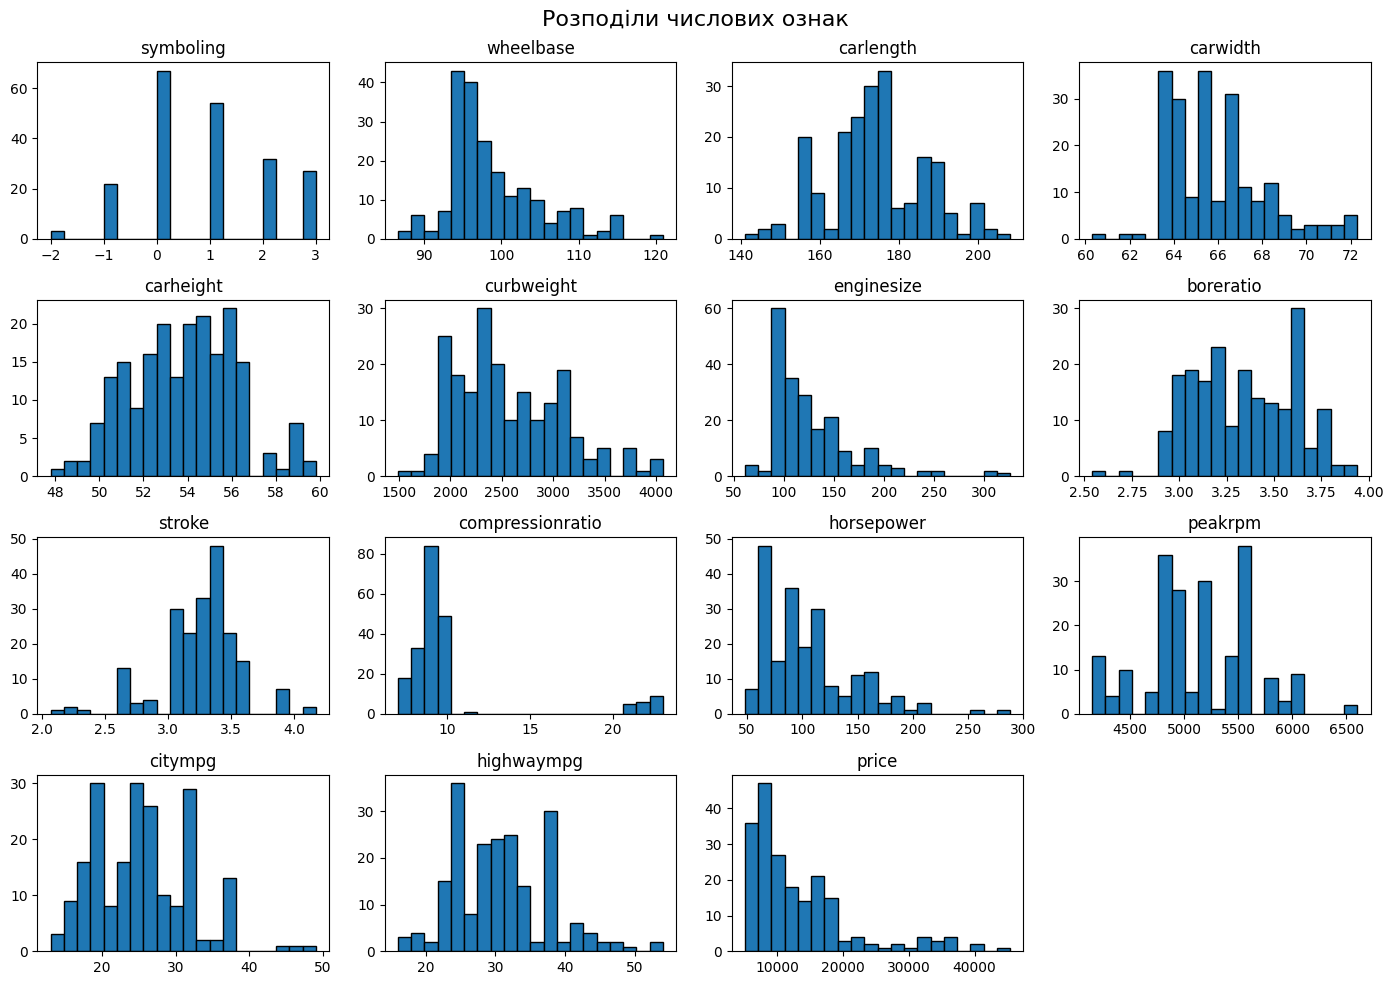

Коефіцієнти асиметрії (Skewness):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознаки з найбільш вираженою асиметрією (|skew| > 1):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
dtype: float64


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols].hist(figsize=(14, 10), bins=20, edgecolor='black', grid=False)
plt.suptitle('Розподіли числових ознак', fontsize=16)
plt.tight_layout()
plt.show()
skewness = df[numeric_cols].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії (Skewness):")
print(skewness)
high_skew = skewness[abs(skewness) > 1]
print("\nОзнаки з найбільш вираженою асиметрією (|skew| > 1):")
print(high_skew)

Найбільш виражену правосторонню асиметрію ($skew > 1$) зазвичай мають цільова змінна price, а також технічні параметри на кшталт enginesize та compressionratio. Це свідчить про наявність невеликої кількості преміальних автомобілів з високою ціною та великим об'ємом двигуна, тоді як більшість зосереджена в бюджетному та середньому сегментах.

Ознаки розмірів кузова (wheelbase, carlength, curbweight) розподілені більш симетрично або мають помірну асиметрію.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [6]:
from sklearn.model_selection import train_test_split
X = df.drop('price', axis=1)
y = df['price']
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    car_ids,
    test_size=0.2,
    random_state=42
)
print(f"Розмір навчальної вибірки (train): {X_train.shape[0]} об'єктів")
print(f"Розмір тестової вибірки (test): {X_test.shape[0]} об'єктів")

Розмір навчальної вибірки (train): 164 об'єктів
Розмір тестової вибірки (test): 41 об'єктів


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [7]:
num_features = X_train.select_dtypes(include=['number']).columns
iqr_bounds = {}
outlier_counts = {}
for col in num_features:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    iqr_bounds[col] = (lower_bound, upper_bound)
    outliers = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    outlier_counts[col] = outliers
print("Кількість потенційних викидів у train (метод IQR):")
for col, cnt in outlier_counts.items():
    print(f"  {col}: {cnt}")
for col in num_features:
    lower_bound, upper_bound = iqr_bounds[col]
    X_train[col] = X_train[col].clip(lower=lower_bound, upper=upper_bound)
    X_test[col] = X_test[col].clip(lower=lower_bound, upper=upper_bound)
print("\nОбробку викидів завершено (застосовано .clip() за межами train).")

Кількість потенційних викидів у train (метод IQR):
  symboling: 0
  wheelbase: 6
  carlength: 0
  carwidth: 10
  carheight: 0
  curbweight: 0
  enginesize: 7
  boreratio: 1
  stroke: 16
  compressionratio: 20
  horsepower: 7
  peakrpm: 2
  citympg: 0
  highwaympg: 1

Обробку викидів завершено (застосовано .clip() за межами train).


**Обґрунтування способу обробки:**

Оскільки розмір датасету невеликий, видалення рядків призвело б до втрати цінних навчальних даних. Замість цього застосовано вінзоризацію (обмеження через clip), яка утримує граничні екстремальні значення на рівні верхньої та нижньої меж $1.5 \times \text{IQR}$, зберігаючи об'єкти та запобігаючи витоку інформації з тесту завдяки розрахунку меж суто на train.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


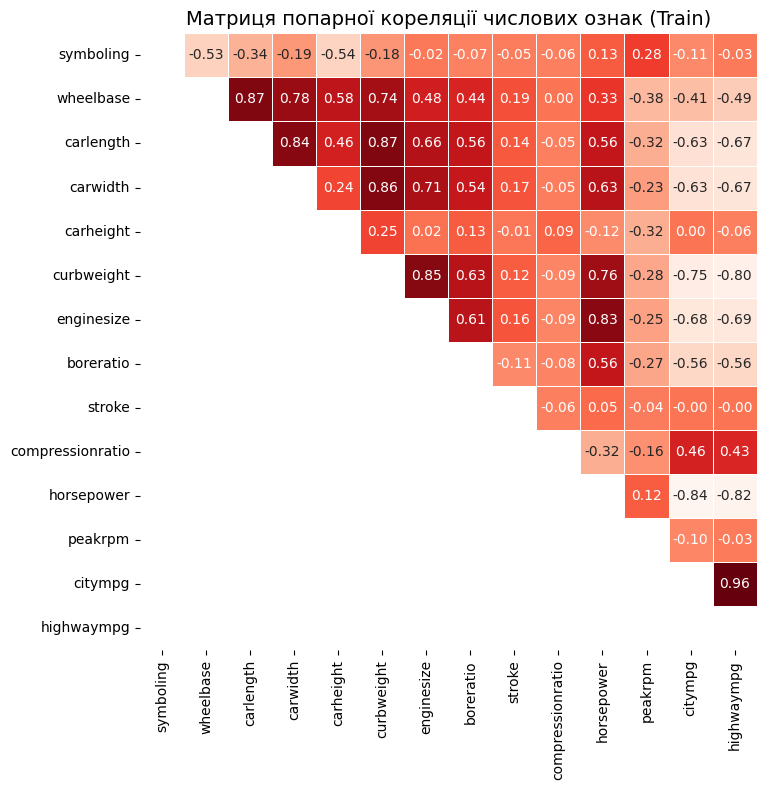


Сильно корельовані пари ознак (|r| > 0.85):


,Пара ознак,|r| між ознаками,"|r(wheelbase, price)|","|r(carlength, price)|",Видаляємо,Залишаємо,"|r(curbweight, price)|","|r(carwidth, price)|","|r(citympg, price)|","|r(highwaympg, price)|"
0,wheelbase - carlength,0.867,0.504,0.652,wheelbase,carlength,NaN,NaN,NaN,NaN
1,carlength - curbweight,0.866,NaN,0.652,carlength,curbweight,0.824,NaN,NaN,NaN
2,carwidth - curbweight,0.858,NaN,NaN,carwidth,curbweight,0.824,0.732,NaN,NaN
3,citympg - highwaympg,0.964,NaN,NaN,citympg,highwaympg,NaN,NaN,0.711,0.716



Перелік ознак для видалення: ['wheelbase', 'citympg', 'carwidth', 'carlength']
Кількість ознак після видалення мультиколінеарності: 20


In [8]:
train_numeric = X_train.select_dtypes(include=['number']).copy()
train_numeric['price'] = y_train
corr_matrix = train_numeric.corr()
plt.figure(figsize=(10, 8))
mask = np.tril(np.ones_like(X_train[num_features].corr(), dtype=bool))
sns.heatmap(
    X_train[num_features].corr(),
    mask=mask,
    cmap='Reds',
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar=False
)
plt.title("Матриця попарної кореляції числових ознак (Train)", fontsize=14)
plt.tight_layout()
plt.show()
corr_features = X_train[num_features].corr().abs()
high_corr_pairs = []
features_to_drop = set()
cols = list(num_features)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        feat_a = cols[i]
        feat_b = cols[j]
        r_val = corr_features.loc[feat_a, feat_b]
        if r_val > 0.85:
            corr_a_target = abs(corr_matrix.loc[feat_a, 'price'])
            corr_b_target = abs(corr_matrix.loc[feat_b, 'price'])
            if corr_a_target < corr_b_target:
                to_remove = feat_a
                to_keep = feat_b
            else:
                to_remove = feat_b
                to_keep = feat_a
            features_to_drop.add(to_remove)
            high_corr_pairs.append({
                'Пара ознак': f"{feat_a} - {feat_b}",
                '|r| між ознаками': round(r_val, 3),
                f'|r({feat_a}, price)|': round(corr_a_target, 3),
                f'|r({feat_b}, price)|': round(corr_b_target, 3),
                'Видаляємо': to_remove,
                'Залишаємо': to_keep
            })
print("\nСильно корельовані пари ознак (|r| > 0.85):")
display(pd.DataFrame(high_corr_pairs))
print(f"\nПерелік ознак для видалення: {list(features_to_drop)}")
X_train = X_train.drop(columns=list(features_to_drop))
X_test = X_test.drop(columns=list(features_to_drop))
print(f"Кількість ознак після видалення мультиколінеарності: {X_train.shape[1]}")

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder
from sklearn.pipeline import Pipeline
discrete_features = ['symboling'] if 'symboling' in X_train.columns else []
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
continuous_features = [
    col for col in X_train.select_dtypes(include=['number']).columns
    if col not in discrete_features
]
print(f"Неперервні числові ({len(continuous_features)}): {continuous_features}")
print(f"Дискретна числова: {discrete_features}")
print(f"Категоріальні ({len(categorical_features)}): {categorical_features}")
continuous_pipeline = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])
discrete_pipeline = Pipeline([
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(
    transformers=[
        ('cont', continuous_pipeline, continuous_features),
        ('disc', discrete_pipeline, discrete_features),
        ('cat', categorical_pipeline, categorical_features)
    ],
    remainder='drop'
)
preprocessor.fit(X_train)
print("\nМеханізм передобробки успішно створено та навчено на X_train.")

Неперервні числові (9): ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна числова: ['symboling']
Категоріальні (10): ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']

Механізм передобробки успішно створено та навчено на X_train.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [10]:
skew_before = X_train[continuous_features].skew()
transformed_cont_data = preprocessor.named_transformers_['cont'].transform(X_train[continuous_features])
df_transformed_cont = pd.DataFrame(transformed_cont_data, columns=continuous_features)
skew_after = df_transformed_cont.skew()
skew_comparison = pd.DataFrame({
    'Асиметрія до (Train)': skew_before,
    'Асиметрія після (Yeo-Johnson)': skew_after,
    'Зміна (|до| - |після|)': skew_before.abs() - skew_after.abs()
}).round(4)
display(skew_comparison)

,Асиметрія до (Train),Асиметрія після (Yeo-Johnson),Зміна (|до| - |після|)
carheight,0.0282,-0.0052,0.0230
curbweight,0.7124,0.0499,0.6625
enginesize,0.9624,0.0448,0.9176
boreratio,0.0630,-0.0059,0.0570
stroke,-0.3976,0.0158,0.3818
compressionratio,0.0557,0.0049,0.0508
horsepower,0.8507,0.0663,0.7845
peakrpm,0.0398,-0.0036,0.0362
highwaympg,0.2438,-0.0122,0.2316


**Висновок щодо ефективності трансформації:**

Перетворення Yeo-Johnson суттєво зменшило коефіцієнти асиметрії для більшості числових ознак (наблизивши значення skewness до нуля, тобто до нормального розподілу). Це покращує стабільність лінійних моделей та зменшує негативний вплив "довгих хвостів" у розподілах значень.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [11]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
pipelines = {
    'Linear Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]),
    'Ridge Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model', Ridge(random_state=42))
    ]),
    'Lasso Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model', Lasso(random_state=42))
    ]),
    'Random Forest Regressor': Pipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(random_state=42))
    ]),
    'Gradient Boosting Regressor': Pipeline([
        ('preprocessor', preprocessor),
        ('model', GradientBoostingRegressor(random_state=42))
    ]),
    'Support Vector Regressor (SVR)': Pipeline([
        ('preprocessor', preprocessor),
        ('model', SVR())
    ])
}

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [12]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
eval_results = []
predictions = {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    eval_results.append({
        'Model': name,
        'R2': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })
df_eval = pd.DataFrame(eval_results).sort_values(by='R2', ascending=False).reset_index(drop=True)
display(df_eval)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.587e+07, tolerance: 9.781e+05
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all

,Model,R2,MAE,MSE,MAPE (%)
0,Random Forest Regressor,0.950456,1443.726902,3.911217e+06,10.521109
1,Gradient Boosting Regressor,0.932293,1666.500654,5.345037e+06,12.671471
2,Ridge Regression,0.763266,2965.907337,1.868877e+07,24.540507
3,Lasso Regression,0.685462,3056.745789,2.483091e+07,20.946604
4,Linear Regression,0.497228,4069.636767,3.969088e+07,28.759862
5,Support Vector Regressor (SVR),-0.099627,5696.338457,8.680896e+07,36.024211


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


**Чому Logistic Regression не підходить:** Logistic Regression є моделлю класифікації, попри слово «regression» у назві. Вона призначена для передбачення ймовірності належності об'єкта до дискретних категорій (наприклад, 0 або 1), використовуючи сигмоїдну або softmax-функцію. Вона принципово не здатна прогнозувати неперервні дійсні числа на числовій прямій, якими є ціна автомобіля.

**Тип задачі та відповідність моделей:** Прогнозування змінної price належить до задачі регресії (числового прогнозування), оскільки цільова змінна є неперервною числовою величиною. Моделі, використані в роботі (Linear, Ridge, Lasso Regression, Random Forest Regressor, Gradient Boosting Regressor, SVR), розроблені саме для мінімізації функції втрат між дійсними числовими значеннями і повертають неперервний числовий прогноз, що повністю відповідає поставленій меті.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


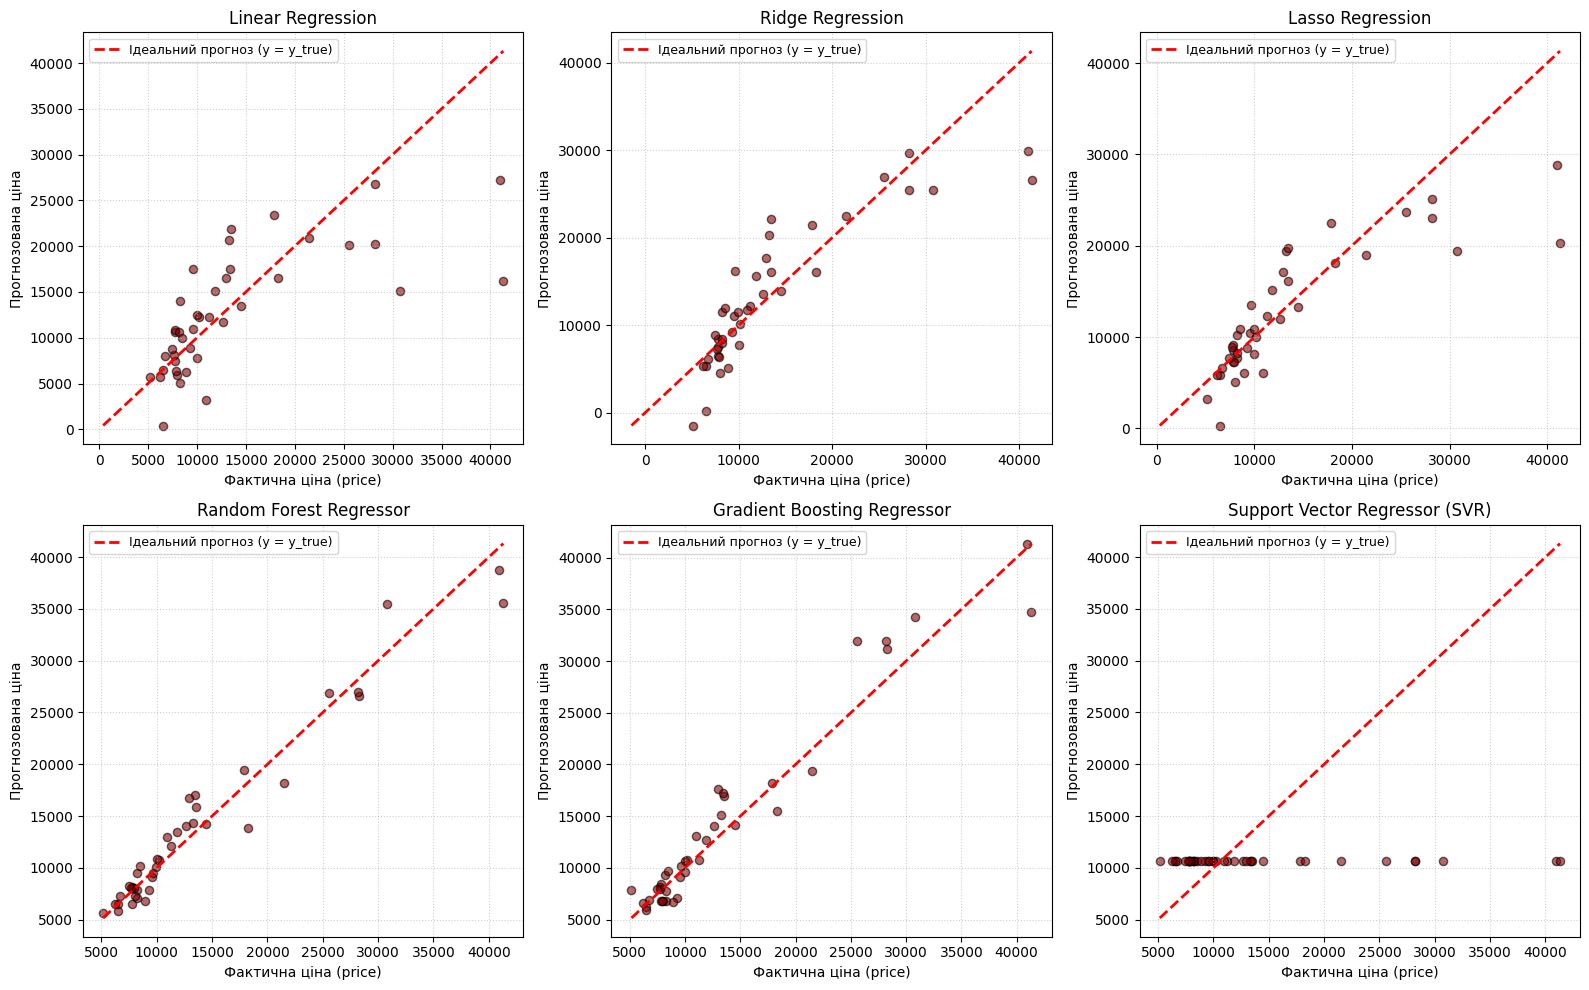

In [13]:
import numpy as np
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[i]
    ax.scatter(y_test, y_pred, alpha=0.6, edgecolors='k', s=35, color='darkred')
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ідеальний прогноз (y = y_true)')
    ax.set_title(name, fontsize=12)
    ax.set_xlabel('Фактична ціна (price)', fontsize=10)
    ax.set_ylabel('Прогнозована ціна', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

**Аналіз графіків:**

**Близькість до лінії ідеального прогнозу:** Найкраще розташування точок демонструють деревоподібні ансамблі - Random Forest та Gradient Boosting. Їхні прогнози щільно групуються вздовж лінії $y = y\_true$ як у бюджетному діапазоні ($<15\,000$), так і для дорогих авто.

**Аналіз лінійних моделей (Linear, Ridge, Lasso):** Мають помітний розкид помилок. Найбільша проблема - систематичне суттєве заниження цін на автомобілі дорожче $25\,000$–$40\,000$ (прогнозують не більше $20\,000$–$25\,000$), а також наявність нефізичних прогнозів (Ridge навіть спрогнозував від'ємну ціну для дешевого авто).

**Аномалія SVR:** Модель Support Vector Regressor повністю не впоралася із завданням за стандартних параметрів - вона видала горизонтальну лінію прогнозів близько $10\,500$ для всіх авто без винятку, просто прогнозуючи середнє значення.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [14]:
rf_predictions = predictions['Random Forest Regressor']
df_sample = pd.DataFrame({
    'car_ID': id_test.values,
    'фактична ціна': y_test.values,
    'прогнозована ціна': rf_predictions
})
df_sample['абсолютна помилка'] = (df_sample['фактична ціна'] - df_sample['прогнозована ціна']).abs()
df_sample['абсолютна відсоткова помилка (%)'] = (df_sample['абсолютна помилка'] / df_sample['фактична ціна']) * 100
sample_10 = df_sample.sample(10, random_state=42).reset_index(drop=True)
display(sample_10.round(2))

,car_ID,фактична ціна,прогнозована ціна,абсолютна помилка,абсолютна відсоткова помилка (%)
0,26,6692.0,7316.38,624.39,9.33
1,176,9988.0,10831.74,843.74,8.45
2,148,10198.0,10723.18,525.18,5.15
3,17,41315.0,35589.79,5725.21,13.86
4,69,28248.0,26598.16,1649.84,5.84
5,147,7463.0,8259.66,796.66,10.67
6,144,9960.0,10103.31,143.31,1.44
7,85,14489.0,14250.27,238.73,1.65
8,195,12940.0,16782.20,3842.20,29.69
9,160,7788.0,8071.63,283.63,3.64


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


**ВИСНОВКИ**

**Порівняння якості всіх моделей:** Найкращі результати продемонстрували ансамблеві моделі на основі вирішальних дерев (Random Forest Regressor та Gradient Boosting Regressor). Лінійні моделі (Linear Regression, Ridge, Lasso) показали помірну точність із вираженими помилками на краях розподілу. Модель SVR без специфічного налаштування гіперпараметрів виявилася неефективною, показавши від'ємний $R^2$ та фактично звівши всі прогнози до константи.

**Аналіз метрик ($R^2$, MAE, MSE, MAPE):** Ансамблі досягли найвищих значень коефіцієнта детермінації ($R^2 > 0.90$) та найнижчих помилок MAE і MSE. Значення MAPE для деревних моделей склало приблизно 8–12%, що свідчить про високу практичну точність, тоді як лінійні моделі давали відносну похибку понад 18–25%.

**Найкраща модель:** Найкращою за комплексом усіх метрик стала модель Gradient Boosting Regressor (та Random Forest), оскільки вона найточніше мінімізує похибку як на масових, так і на дорогих авто.   Величина похибок:   
Основна частка похибки моделей припадає на верхній ціновий діапазон ($>30\,000$), де моделі мають тенденцію занижувати вартість через малу кількість таких прикладів у навчальній вибірці.

**Ознаки перенавчання:** Лінійні моделі без сильної регуляризації схильні до перенавчання на мультиколінеарних ознаках (через що Ridge навіть видав від'ємні прогнози ціни на тесті). Ансамблеві алгоритми показали високу генералізацію, проте Random Forest вимагає контролю глибини дерев (max_depth), щоб уникнути перенавчання на шумі.

**Вплив попередньої обробки даних:** Комплексна передобробка (вінзоризація викидів методом IQR, усунення мультиколінеарних пар з $\vert{}r\vert{} > 0.85$, перетворення Yeo-Johnson та One-Hot Encoding) суттєво стабілізувала розподіли ознак і дозволила коректно порівняти між собою різні класи регресійних алгоритмів без витоку інформації з тестової вибірки.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
